# Temporary check: why is Seattle's transit commute so long?

05.3.3 gives a worker-weighted transit median far above the car's. This notebook takes the Seattle matrices
apart to say where the minutes go: the transit time is the one 05.3.3 writes, with the walk to the first stop
and from the last stop capped at 30 minutes. It is a scratch notebook: nothing here feeds the pipeline, and it
reads the artifacts 05.3.3 left on scratch.

Questions, in order: the real mean and median, weighted and not; how the time grows with distance; the
city centre against the suburbs; how much of a "transit" time is only walking; the legs of a sample of
journeys (access walk, waits, rides, transfers, egress); and how much a single 08:30 departure costs
against the median over a one-hour window.

In [1]:
import time
import zipfile
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shapely

from cafein import StreetNetwork, TransportNetwork, TravelTimeMatrix, DetailedItineraries
from cafein._streaming import read_shards

YEAR = 2023
RESULTS = Path("/scratch/project_2010423/carbon-advantage/commuting/seattle")
MATRICES = RESULTS / "matrices"
STREET_ARTIFACT = RESULTS / "seattle-streets.cafein"
TRANSIT_ARTIFACT = RESULTS / "seattle-transit.cafein"
DEPARTURE = "2026-11-10 08:30"
ACCESS_EGRESS_WALK_MIN = 30                # as in 05.3.3 and 05.10
METRIC_CRS = "EPSG:32610"

CENTRE = (-122.3372, 47.6115)            # Westlake station, downtown Seattle
RINGS = [0, 3, 8, 15, 30, 1000]
RING_LABELS = ["centre (<3 km)", "3-8 km", "8-15 km", "15-30 km", ">30 km"]

SAMPLE_PAIRS = 300                        # journeys taken apart leg by leg, drawn with probability proportional to workers
CENTRE_PAIRS = 100                        # plus the heaviest flows into the centre
SAMPLE_ORIGINS = 120                      # home points re-routed over a departure window
WINDOW_START, WINDOW_MIN = "2026-11-10 07:30", 60
SEED = 1
FIG = Path("figures")
FIG.mkdir(exist_ok=True)

## 1. Load

In [2]:
od = pd.read_parquet(MATRICES / f"tract-od-times-{YEAR}.parquet")
points = gpd.read_parquet(RESULTS / f"tract-points-{YEAR}.parquet")
tracts = gpd.read_parquet(RESULTS / f"tracts-kept-{YEAR}.parquet")
for frame, column in ((od, "from_id"), (od, "to_id"), (points, "id"), (tracts, "tract")):
    frame[column] = frame[column].astype(str)

centre = gpd.GeoSeries([shapely.Point(CENTRE)], crs="EPSG:4326").to_crs(METRIC_CRS).iloc[0]
points["km_to_centre"] = points.to_crs(METRIC_CRS).distance(centre) / 1000
points["ring"] = pd.cut(points["km_to_centre"], RINGS, labels=RING_LABELS, include_lowest=True)
ring = points.set_index("id")["ring"]
od["home_ring"] = od["from_id"].map(ring)
od["work_ring"] = od["to_id"].map(ring)
od["same_tract"] = od["from_id"] == od["to_id"]
od["ratio"] = od["transit_min"] / od["car_min"]
print(f"{len(od):,} tract pairs, {od['workers'].sum():,} workers, {len(points)} routing points")
print("workers by home ring:")
display(od.groupby("home_ring", observed=False)["workers"].sum().to_frame().T)
print("workers by work ring:")
display(od.groupby("work_ring", observed=False)["workers"].sum().to_frame().T)

253,835 tract pairs, 1,531,980 workers, 791 routing points
workers by home ring:


home_ring,centre (<3 km),3-8 km,8-15 km,15-30 km,>30 km
workers,81385,141867,241380,482282,585066


workers by work ring:


work_ring,centre (<3 km),3-8 km,8-15 km,15-30 km,>30 km
workers,292132,164613,224034,440809,410392


## 2. The real mean and median

Worker-weighted (every commute counts as many times as it has workers) and per tract pair (each pair once),
with and without the pairs inside one tract, whose times are short and pull the medians down.

In [3]:
def wquant(values, weights, q):
    order = np.argsort(values)
    cumulative = np.cumsum(weights[order]) / weights.sum()
    return float(values[order][min(np.searchsorted(cumulative, q), len(values) - 1)])


def wstats(values, weights):
    return {"mean": np.average(values, weights=weights), **{f"p{int(q * 100)}": wquant(values, weights, q) for q in (0.25, 0.5, 0.75, 0.9)}}


rows = {}
for mode in ("car", "transit", "bicycle"):
    for label, mask in (("all pairs", od[f"{mode}_min"].notna()), ("between different tracts", od[f"{mode}_min"].notna() & ~od["same_tract"])):
        values = od.loc[mask, f"{mode}_min"].to_numpy()
        weights = od.loc[mask, "workers"].to_numpy()
        rows[(mode, label, "worker-weighted")] = wstats(values, weights)
        rows[(mode, label, "per tract pair")] = wstats(values, np.ones_like(values))
stats = pd.DataFrame(rows).T.round(1)
stats.index.names = ["mode", "pairs", "weighting"]
display(stats)

reached = od["transit_min"].notna()
total = od["workers"].sum()
print("share of all workers with a transit time ...")
display(pd.Series({f"over {t} min": od.loc[reached & (od["transit_min"] > t), "workers"].sum() / total for t in (45, 60, 90, 120, 180)}
                  | {"not reached": 1 - od.loc[reached, "workers"].sum() / total}).round(3).to_frame("share").T)
both = reached & od["car_min"].notna() & (od["car_min"] > 0)
print("transit time divided by car (rush) time, worker-weighted percentiles:")
display(pd.Series(wstats(od.loc[both, "ratio"].to_numpy(), od.loc[both, "workers"].to_numpy())).round(2).to_frame("transit / car").T)
print(f"share of workers with transit within 15 minutes of the car: {od.loc[both & (od['transit_min'] <= od['car_min'] + 15), 'workers'].sum() / od.loc[both, 'workers'].sum():.1%}")

mean   p25    p50    p75  \
mode    pairs                    weighting                                    
car     all pairs                worker-weighted   37.2  23.9   34.6   47.6   
                                 per tract pair    49.8  33.8   46.7   63.1   
        between different tracts worker-weighted   38.1  24.7   35.1   48.0   
                                 per tract pair    50.0  34.0   46.8   63.2   
transit all pairs                worker-weighted   86.4  52.9   77.7  109.1   
                                 per tract pair   115.7  75.2  105.4  142.5   
        between different tracts worker-weighted   88.7  54.8   79.0  110.0   
                                 per tract pair   116.2  75.7  105.8  142.7   
bicycle all pairs                worker-weighted   55.3  28.4   53.4   81.3   
                                 per tract pair    66.7  41.7   68.3   92.4   
        between different tracts worker-weighted   57.0  30.5   54.9   82.1   
                                 per tract pair    67.1  42.2   68.6   92.6   

                                                    p90  
mode    pairs                    weighting               
car     all pairs                worker-weighted   62.9  
                                 per tract pair    81.4  
        between different tracts worker-weighted   63.3  
                                 per tract pair    81.5  
transit all pairs                worker-weighted  146.1  
                                 per tract pair   183.6  
        between different tracts worker-weighted  147.1  
                                 per tract pair   183.8  
bicycle all pairs                worker-weighted  101.2  
                                 per tract pair   108.2  
        between different tracts worker-weighted  101.7  
                                 per tract pair   108.3

share of all workers with a transit time ...


,over 45 min,over 60 min,over 90 min,over 120 min,over 180 min,not reached
share,0.693,0.574,0.331,0.162,0.035,0.153


transit time divided by car (rush) time, worker-weighted percentiles:


,mean,p25,p50,p75,p90
transit / car,2.54,2.0,2.35,2.83,3.42


share of workers with transit within 15 minutes of the car: 6.9%


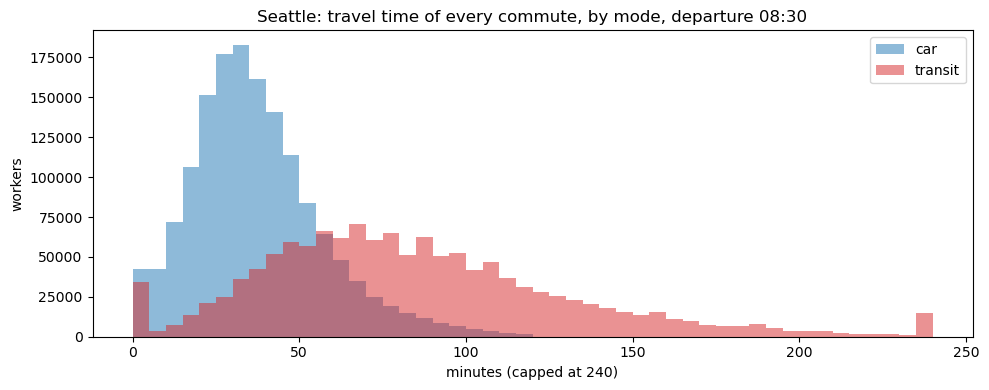

In [4]:
fig, ax = plt.subplots(figsize=(10, 4))
bins = np.arange(0, 245, 5)
for mode, colour in (("car", "tab:blue"), ("transit", "tab:red")):
    mask = od[f"{mode}_min"].notna()
    ax.hist(od.loc[mask, f"{mode}_min"].clip(upper=240), bins=bins, weights=od.loc[mask, "workers"], alpha=0.5, color=colour, label=mode)
ax.set_xlabel("minutes (capped at 240)")
ax.set_ylabel("workers")
ax.set_title("Seattle: travel time of every commute, by mode, departure 08:30")
ax.legend()
fig.tight_layout()
fig.savefig(FIG / "tmp-transit-check-histogram.png", dpi=120)

## 3. Does it grow with distance?

Straight-line distance between the routing points of the two tracts. The implied speed is the straight-line
kilometres per hour of travel time, worker-weighted.

In [5]:
bands = pd.cut(od["straight_km"], [0, 2, 5, 10, 15, 20, 30, 50, 500], include_lowest=True)
rows = []
for band, group in od.groupby(bands, observed=False):
    row = {"straight-line km": str(band), "workers": group["workers"].sum()}
    for mode in ("car", "transit"):
        mask = group[f"{mode}_min"].notna()
        if mask.any():
            values = group.loc[mask, f"{mode}_min"].to_numpy(); weights = group.loc[mask, "workers"].to_numpy()
            row[f"{mode} median min"] = wquant(values, weights, 0.5)
            row[f"{mode} reached"] = weights.sum() / group["workers"].sum()
            moving = values > 0
            row[f"{mode} km/h"] = (group.loc[mask, "straight_km"].to_numpy()[moving] * weights[moving]).sum() / ((values[moving] / 60) * weights[moving]).sum()
    rows.append(row)
by_distance = pd.DataFrame(rows).set_index("straight-line km")
by_distance["transit / car"] = by_distance["transit median min"] / by_distance["car median min"]
display(by_distance.round(2))

,workers,car median min,car reached,car km/h,transit median min,transit reached,transit km/h,transit / car
straight-line km,,,,,,,,
"(-0.001, 2.0]",97566,6.22,1.00,9.45,16.13,0.98,3.13,2.60
"(2.0, 5.0]",166915,17.22,0.99,11.93,42.50,0.91,4.58,2.47
"(5.0, 10.0]",296254,26.33,0.99,16.68,59.05,0.88,7.00,2.24
"(10.0, 15.0]",260125,32.75,0.99,22.24,75.12,0.86,9.26,2.29
"(15.0, 20.0]",206795,38.00,0.99,26.71,87.83,0.82,11.05,2.31
"(20.0, 30.0]",242124,45.48,0.99,31.32,107.20,0.79,12.75,2.36
"(30.0, 50.0]",180042,58.63,0.99,38.28,132.40,0.80,16.57,2.26
"(50.0, 500.0]",82159,82.83,0.96,44.95,180.15,0.70,19.99,2.17


## 4. City centre against suburbs

Rings of distance from Westlake station: the home ring down the rows, the work ring across. Worker-weighted
median minutes by transit, then by car, then the workers on each cell.

In [6]:
def ring_pivot(column, how):
    table = {}
    for (home, work), group in od.groupby(["home_ring", "work_ring"], observed=False):
        if how == "workers":
            table[(home, work)] = group["workers"].sum()
        else:
            mask = group[column].notna()
            if mask.any():
                table[(home, work)] = wquant(group.loc[mask, column].to_numpy(), group.loc[mask, "workers"].to_numpy(), 0.5)
    return pd.Series(table).unstack().reindex(index=RING_LABELS, columns=RING_LABELS)

for column, title in (("transit_min", "transit, median minutes"), ("car_min", "car (rush), median minutes"), ("workers", "workers")):
    print(title + " (home ring down, work ring across):")
    display(ring_pivot(column, "workers" if column == "workers" else "median").round(0))

print("commutes into the centre, by home ring:")
into = od.loc[od["work_ring"] == RING_LABELS[0]]
rows = {}
for home, group in into.groupby("home_ring", observed=False):
    mask = group["transit_min"].notna()
    cars = group["car_min"].notna()
    rows[home] = {"workers": group["workers"].sum(), "transit reached": group.loc[mask, "workers"].sum() / max(group["workers"].sum(), 1),
                  "transit median": wquant(group.loc[mask, "transit_min"].to_numpy(), group.loc[mask, "workers"].to_numpy(), 0.5) if mask.any() else np.nan,
                  "car median": wquant(group.loc[cars, "car_min"].to_numpy(), group.loc[cars, "workers"].to_numpy(), 0.5) if cars.any() else np.nan,
                  "straight km median": wquant(group["straight_km"].to_numpy(), group["workers"].to_numpy(), 0.5) if len(group) else np.nan}
display(pd.DataFrame(rows).T.round(1))

transit, median minutes (home ring down, work ring across):


,centre (<3 km),3-8 km,8-15 km,15-30 km,>30 km
centre (<3 km),20.0,38.0,55.0,63.0,107.0
3-8 km,41.0,43.0,69.0,81.0,122.0
8-15 km,56.0,60.0,62.0,77.0,130.0
15-30 km,84.0,89.0,90.0,72.0,109.0
>30 km,114.0,122.0,139.0,122.0,81.0


car (rush), median minutes (home ring down, work ring across):


,centre (<3 km),3-8 km,8-15 km,15-30 km,>30 km
centre (<3 km),8.0,19.0,26.0,31.0,57.0
3-8 km,20.0,20.0,33.0,39.0,62.0
8-15 km,27.0,30.0,24.0,33.0,58.0
15-30 km,37.0,42.0,35.0,29.0,45.0
>30 km,58.0,62.0,59.0,49.0,32.0


workers (home ring down, work ring across):


,centre (<3 km),3-8 km,8-15 km,15-30 km,>30 km
centre (<3 km),37037,12313,13833,14868,3334
3-8 km,50470,33071,24094,26366,7866
8-15 km,68922,39813,54667,62554,15424
15-30 km,86247,46790,84805,200371,64069
>30 km,49456,32626,46635,136650,319699


commutes into the centre, by home ring:


,workers,transit reached,transit median,car median,straight km median
centre (<3 km),37037.0,1.0,19.6,7.9,1.3
3-8 km,50470.0,1.0,40.9,20.3,5.7
8-15 km,68922.0,1.0,55.8,27.0,10.6
15-30 km,86247.0,0.9,83.9,36.6,20.4
>30 km,49456.0,0.8,114.5,57.7,39.9


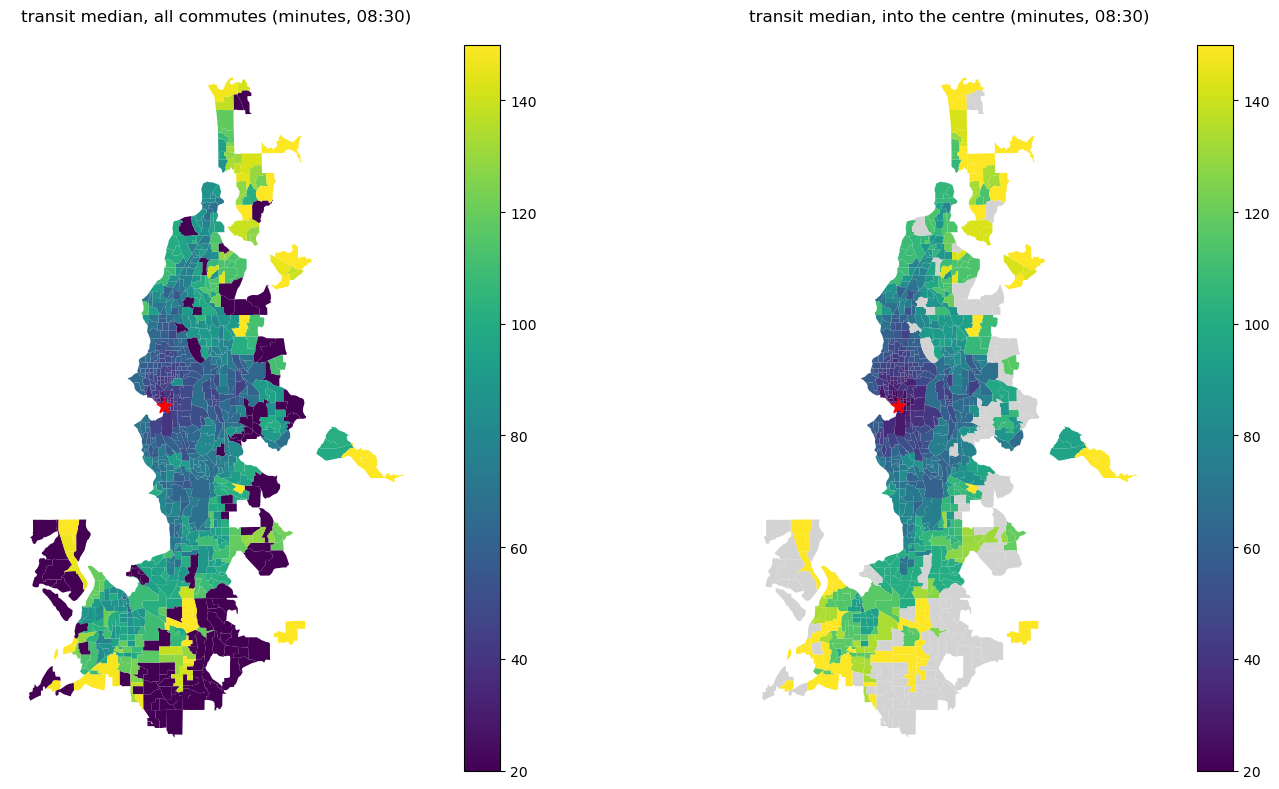

In [7]:
# Map: median transit minutes by home tract, and the same for commutes into the centre only.
def median_by_home(table):
    out = {}
    for home, group in table.groupby("from_id"):
        mask = group["transit_min"].notna()
        out[home] = wquant(group.loc[mask, "transit_min"].to_numpy(), group.loc[mask, "workers"].to_numpy(), 0.5) if mask.any() else np.nan
    return pd.Series(out)

maps = tracts.set_index("tract").to_crs(METRIC_CRS)
maps["transit median, all commutes"] = median_by_home(od)
maps["transit median, into the centre"] = median_by_home(into)
fig, axes = plt.subplots(1, 2, figsize=(16, 8))
for ax, column in zip(axes, ["transit median, all commutes", "transit median, into the centre"]):
    maps.plot(column=column, ax=ax, cmap="viridis", vmin=20, vmax=150, legend=True, missing_kwds={"color": "lightgrey"}, linewidth=0)
    ax.scatter(*centre.coords[0], marker="*", color="red", s=120)
    ax.set_title(column + " (minutes, 08:30)")
    ax.set_axis_off()
fig.tight_layout()
fig.savefig(FIG / "tmp-transit-check-map.png", dpi=110)

## 5. How much of it is just walking?

cafein lets a journey be a door-to-door walk when no ride beats it, within the walking cap, so a "transit"
time can be a walk. The walking matrix on the street network says which pairs those are.

In [8]:
started = time.time()
streets = StreetNetwork.load(STREET_ARTIFACT)
walk = TravelTimeMatrix(streets, points[["id", "geometry"]], points[["id", "geometry"]], transport_mode="walk", max_street_time=ACCESS_EGRESS_WALK_MIN, output_time_units="seconds")
walk = pd.DataFrame(walk)[["from_id", "to_id", "travel_time"]].rename(columns={"travel_time": "walk_min"})
walk["walk_min"] = walk["walk_min"] / 60
walk["from_id"] = walk["from_id"].astype(str); walk["to_id"] = walk["to_id"].astype(str)
od = od.drop(columns=[c for c in ["walk_min"] if c in od.columns]).merge(walk, on=["from_id", "to_id"], how="left")
print(f"walking matrix in {time.time() - started:.0f} s; {od['walk_min'].notna().sum():,} pairs within {ACCESS_EGRESS_WALK_MIN} minutes on foot")

reached = od["transit_min"].notna()
od["walk_only"] = reached & od["walk_min"].notna() & (od["transit_min"] >= od["walk_min"] - 0.5)
print(f"transit time that is only a walk: {od.loc[od['walk_only'], 'workers'].sum() / od.loc[reached, 'workers'].sum():.1%} of the reached workers, "
      f"median {wquant(od.loc[od['walk_only'], 'transit_min'].to_numpy(), od.loc[od['walk_only'], 'workers'].to_numpy(), 0.5):.0f} min")
rides = reached & ~od["walk_only"]
print("transit minutes, worker-weighted, journeys with at least one ride only:")
display(pd.Series(wstats(od.loc[rides, "transit_min"].to_numpy(), od.loc[rides, "workers"].to_numpy())).round(1).to_frame("minutes").T)
print("share of reached workers with a walk-only transit time, by home ring:")
display(od.loc[reached].groupby("home_ring", observed=False).apply(lambda g: g.loc[g["walk_only"], "workers"].sum() / max(g["workers"].sum(), 1)).round(3).to_frame("walk only").T)

walking matrix in 2 s; 2,195 pairs within 30 minutes on foot
transit time that is only a walk: 3.5% of the reached workers, median 0 min
transit minutes, worker-weighted, journeys with at least one ride only:


,mean,p25,p50,p75,p90
minutes,89.4,55.6,79.4,110.4,147.6


share of reached workers with a walk-only transit time, by home ring:


/tmp/marinflo/3371611/ipykernel_1246184/2902503888.py:18: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  display(od.loc[reached].groupby("home_ring", observed=False).apply(lambda g: g.loc[g["walk_only"], "workers"].sum() / max(g["workers"].sum(), 1)).round(3).to_frame("walk only").T)


home_ring,centre (<3 km),3-8 km,8-15 km,15-30 km,>30 km
walk only,0.117,0.033,0.025,0.027,0.035


## 6. The legs of the journeys

A sample of commutes, each routed door to door with the full itinerary: the access walk, the wait at the first
stop, the rides, the transfers (walk and wait), the egress walk. Drawn with probability proportional to the
workers, plus the heaviest flows into the centre. The fastest option per pair is kept, and its duration is
checked against the matrix.

In [9]:
started = time.time()
transit_network = TransportNetwork.load(TRANSIT_ARTIFACT)
route_types = {route_id: route_type for route_id, _agency, route_type in transit_network.routes}
TYPE_NAMES = {0: "tram/light rail", 1: "metro", 2: "rail", 3: "bus", 4: "ferry", 12: "monorail"}
print(f"network loaded in {time.time() - started:.0f} s; {len(route_types):,} routes")

rng = np.random.default_rng(SEED)
candidates = od.loc[od["transit_min"].notna() & ~od["same_tract"]].reset_index(drop=True)
drawn = rng.choice(len(candidates), size=SAMPLE_PAIRS, replace=False, p=candidates["workers"] / candidates["workers"].sum())
sample = candidates.iloc[drawn]
heaviest = candidates.loc[candidates["work_ring"] == RING_LABELS[0]].nlargest(CENTRE_PAIRS, "workers")
sample = pd.concat([sample.assign(draw="random, by workers"), heaviest.assign(draw="heaviest into the centre")]).drop_duplicates(["from_id", "to_id"]).reset_index(drop=True)
print(f"{len(sample)} pairs to route, {sample['from_id'].nunique()} distinct homes")

geometry = points.set_index("id")["geometry"]
legs = []
started = time.time()
for home, group in sample.groupby("from_id"):
    origins = gpd.GeoDataFrame({"id": [home]}, geometry=[geometry[home]], crs=points.crs)
    destinations = gpd.GeoDataFrame({"id": group["to_id"].tolist()}, geometry=geometry[group["to_id"]].tolist(), crs=points.crs)
    try:
        result = DetailedItineraries(transit_network, origins, destinations, departure=DEPARTURE, max_walking_time=ACCESS_EGRESS_WALK_MIN, geometries=False, output_time_units="seconds")
        legs.append(pd.DataFrame(result.drop(columns=[c for c in ["geometry"] if c in result.columns])))
    except Exception as error:
        print(f"{home}: {type(error).__name__}: {str(error)[:200]}")
legs = pd.concat(legs, ignore_index=True)
legs["from_id"] = legs["from_id"].astype(str); legs["to_id"] = legs["to_id"].astype(str)
print(f"{len(legs):,} legs of {legs.groupby(['from_id', 'to_id']).ngroups} pairs in {time.time() - started:.0f} s")
legs.head(12)

loading the network:   0%|          | 0/2 [00:02<?, ?it/s]

network loaded in 4 s; 529 routes
396 pairs to route, 299 distinct homes


3,355 legs of 395 pairs in 8 s


,from_id,to_id,option,segment,leg_type,departure_s,arrival_s,travel_time,from_stop,to_stop,trip_id,route_id,route_short_name,distance_m,distance_provenance,emissions
0,53033000300,53033008102,0,0,access,30600,32076,1476,None,11:N13-T2,None,None,None,1475.585144,None,0.000000
1,53033000300,53033008102,0,1,transit,32160,33390,1230,11:N13-T2,11:455,11:LLR_2026-10-19_20260903_Link_Fall26PHActive...,11:2LINE,2 Line,15064.996094,shape_linref,376.624902
2,53033000300,53033008102,0,2,egress,33390,33508,118,11:455,None,None,None,None,117.316060,None,0.000000
3,53033000300,53033008102,1,0,access,30600,31091,491,None,14:17880,None,None,None,490.566672,None,0.000000
4,53033000300,53033008102,1,1,transit,31193,31620,427,14:17880,14:81301,14:871818591,14:102744,365,6841.601562,shape_dist,629.427344
5,53033000300,53033008102,1,2,transfer,31620,31687,67,14:81301,11:N15-T2,None,None,None,66.861622,None,0.000000
6,53033000300,53033008102,1,3,transit,31800,33150,1350,11:N15-T2,11:455,11:LLR_2026-10-19_20260903_Link_Fall26PHActive...,11:100479,1 Line,16434.570312,shape_linref,410.864258
7,53033000300,53033008102,1,4,egress,33150,33268,118,11:455,None,None,None,None,117.316060,None,0.000000
8,53033000402,53033008101,0,0,access,30600,31498,898,None,14:7010,None,None,None,897.933619,None,0.000000
9,53033000402,53033008101,0,1,transit,31763,33780,2017,14:7010,14:431,14:849269261,14:102615,E Line,41805.000000,shape_dist,3846.060000


In [10]:
START_S = (pd.Timestamp(DEPARTURE) - pd.Timestamp(DEPARTURE).normalize()).total_seconds()

def take_apart(journey):
    journey = journey.sort_values("segment")
    arrival = journey["arrival_s"].max()
    duration = (arrival - START_S) / 60
    parts = {"total min": duration}
    for kind, name in (("access", "access walk min"), ("egress", "egress walk min"), ("transfer", "transfer walk min"), ("walk", "walk min")):
        parts[name] = journey.loc[journey["leg_type"] == kind, "travel_time"].sum() / 60
    transit = journey.loc[journey["leg_type"] == "transit"]
    parts["ride min"] = transit["travel_time"].sum() / 60
    parts["rides"] = len(transit)
    parts["wait min"] = duration - sum(parts[k] for k in parts if k.endswith("walk min")) - parts["ride min"]
    first = transit["departure_s"].min() if len(transit) else np.nan
    access_end = journey.loc[journey["leg_type"] == "access", "arrival_s"].max() if (journey["leg_type"] == "access").any() else START_S
    parts["first wait min"] = (first - access_end) / 60 if len(transit) else 0.0
    parts["transfer wait min"] = parts["wait min"] - parts["first wait min"]
    types = {TYPE_NAMES.get(route_types.get(r, -1), "other") for r in transit["route_id"]} if len(transit) else {"walk only"}
    parts["modes"] = " + ".join(sorted(types))
    parts["uses rail"] = any(t in types for t in ("tram/light rail", "metro", "rail", "monorail"))
    return pd.Series(parts)

# Fastest option per pair: the earliest arrival.
arrival_by_option = legs.groupby(["from_id", "to_id", "option"])["arrival_s"].max()
best = arrival_by_option.groupby(level=[0, 1]).idxmin()
fastest = legs.set_index(["from_id", "to_id", "option"]).loc[list(best)].reset_index()
journeys = fastest.groupby(["from_id", "to_id"]).apply(take_apart).reset_index()
journeys = journeys.merge(sample[["from_id", "to_id", "workers", "straight_km", "transit_min", "car_min", "home_ring", "work_ring", "draw"]], on=["from_id", "to_id"])
journeys["matrix minus itinerary"] = journeys["transit_min"] - journeys["total min"]
print("check against the matrix (minutes): ")
display(journeys["matrix minus itinerary"].describe().round(1).to_frame().T)

parts = ["access walk min", "first wait min", "ride min", "transfer walk min", "transfer wait min", "egress walk min", "walk min"]
w = journeys["workers"].to_numpy()
print("minutes per journey, worker-weighted mean, and share of the total:")
means = pd.Series({p: np.average(journeys[p], weights=w) for p in parts + ["total min"]})
display(pd.DataFrame({"mean min": means, "share": means / means["total min"]}).round(2).T)
print("by draw:")
display(journeys.groupby("draw").apply(lambda g: pd.Series({p: np.average(g[p], weights=g["workers"]) for p in parts + ["total min", "car_min", "straight_km", "rides"]})).round(1))
print("rides per journey (share of workers):")
display((journeys.groupby("rides")["workers"].sum() / journeys["workers"].sum()).round(3).to_frame().T)
print("modes used (share of workers) and their median total minutes:")
display(journeys.groupby("modes").apply(lambda g: pd.Series({"share of workers": g["workers"].sum() / journeys["workers"].sum(), "median total min": wquant(g["total min"].to_numpy(), g["workers"].to_numpy(), 0.5), "median car min": wquant(g["car_min"].to_numpy(), g["workers"].to_numpy(), 0.5)})).round(2).sort_values("share of workers", ascending=False))
journeys.to_parquet(MATRICES / "tmp-transit-check-journeys.parquet", index=False)

check against the matrix (minutes): 


/tmp/marinflo/3371611/ipykernel_1246184/1475723755.py:27: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  journeys = fastest.groupby(["from_id", "to_id"]).apply(take_apart).reset_index()


,count,mean,std,min,25%,50%,75%,max
matrix minus itinerary,395.0,-0.8,3.7,-41.4,-0.4,-0.2,-0.0,0.0


minutes per journey, worker-weighted mean, and share of the total:


,access walk min,first wait min,ride min,transfer walk min,transfer wait min,egress walk min,walk min,total min
mean min,10.03,3.65,24.94,1.44,2.10,5.50,1.05,48.7
share,0.21,0.07,0.51,0.03,0.04,0.11,0.02,1.0


by draw:


... (3 outputs left out)

rides,0,1,2,3,4,5,8
workers,0.073,0.338,0.41,0.163,0.013,0.001,0.0


modes used (share of workers) and their median total minutes:


/tmp/marinflo/3371611/ipykernel_1246184/1475723755.py:43: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  display(journeys.groupby("modes").apply(lambda g: pd.Series({"share of workers": g["workers"].sum() / journeys["workers"].sum(), "median total min": wquant(g["total min"].to_numpy(), g["workers"].to_numpy(), 0.5), "median car min": wquant(g["car_min"].to_numpy(), g["workers"].to_numpy(), 0.5)})).round(2).sort_values("share of workers", ascending=False))


,share of workers,median total min,median car min
modes,,,
bus,0.70,46.13,22.35
bus + tram/light rail,0.19,58.60,27.87
walk only,0.07,12.28,4.90
tram/light rail,0.03,32.47,15.08
bus + rail,0.00,196.27,53.38


In [11]:
print("the twenty slowest journeys of the sample:")
columns = ["from_id", "to_id", "workers", "straight_km", "total min", "car_min", "access walk min", "first wait min", "ride min", "transfer walk min", "transfer wait min", "egress walk min", "rides", "modes", "home_ring", "work_ring"]
display(journeys.sort_values("total min", ascending=False)[columns].head(20).round(1))
print("the heaviest flows into the centre:")
display(journeys.loc[journeys["draw"] == "heaviest into the centre"].sort_values("workers", ascending=False)[columns].head(20).round(1))

the twenty slowest journeys of the sample:


,from_id,to_id,workers,straight_km,total min,car_min,access walk min,first wait min,ride min,transfer walk min,transfer wait min,egress walk min,rides,modes,home_ring,work_ring
394,53061053604,53033031710,6,80.4,271.5,NaN,27.8,7.2,198.3,12.4,18.2,7.6,5,bus + tram/light rail,>30 km,>30 km
339,53053940010,53053072508,11,29.9,230.0,53.7,27.8,39.6,124.8,10.2,17.2,10.5,4,bus,>30 km,>30 km
383,53061052504,53033032319,13,23.3,219.3,44.5,28.9,41.1,117.4,7.1,14.5,10.3,4,bus,>30 km,15-30 km
390,53061052706,53033030102,1,75.9,211.2,91.0,15.8,17.2,148.5,5.2,6.3,18.2,4,bus + tram/light rail,>30 km,>30 km
332,53053073126,53033023601,1,58.7,201.4,86.5,21.6,0.1,145.8,3.6,3.4,27.0,3,bus + tram/light rail,>30 km,8-15 km
327,53053072307,53061042004,1,75.0,199.7,106.8,17.4,0.2,149.7,13.7,12.0,6.7,5,bus + tram/light rail,>30 km,15-30 km
313,53053071305,53033023701,3,56.2,198.9,71.8,27.6,6.5,121.4,8.6,11.9,22.9,5,bus + tram/light rail,>30 km,8-15 km
382,53061052504,53033009200,3,43.8,196.3,53.4,28.9,41.1,100.0,5.5,14.5,6.3,4,bus + rail,>30 km,centre (<3 km)
358,53061041907,53033029504,2,59.3,195.4,87.7,28.2,9.8,121.5,7.2,19.3,9.4,5,bus + tram/light rail,>30 km,15-30 km
385,53061052505,53033025103,3,54.6,189.9,73.3,24.8,17.2,121.6,4.2,10.3,11.9,4,bus + tram/light rail,>30 km,15-30 km


the heaviest flows into the centre:


,from_id,to_id,workers,straight_km,total min,car_min,access walk min,first wait min,ride min,transfer walk min,transfer wait min,egress walk min,rides,modes,home_ring,work_ring
91,53033007302,53033007303,909,0.5,8.2,3.1,0.9,0.3,1.8,0.0,-0.0,5.2,1,bus,centre (<3 km),centre (<3 km)
83,53033007201,53033007303,560,0.9,17.5,6.4,0.0,0.0,0.0,0.0,0.0,0.0,0,walk only,centre (<3 km),centre (<3 km)
69,53033006701,53033007303,549,1.3,16.1,7.6,3.2,3.3,4.5,0.0,-0.0,5.1,1,bus,centre (<3 km),centre (<3 km)
85,53033007202,53033007303,520,0.8,11.3,5.0,1.7,1.2,4.9,0.0,0.1,3.3,2,bus + tram/light rail,centre (<3 km),centre (<3 km)
87,53033007301,53033007303,511,0.4,7.9,2.7,0.0,0.0,0.0,0.0,0.0,0.0,0,walk only,centre (<3 km),centre (<3 km)
184,53033022803,53033007303,499,15.7,43.7,23.4,14.8,0.2,25.1,0.0,1.9,1.7,2,bus,15-30 km,centre (<3 km)
86,53033007203,53033007303,494,0.6,10.9,4.9,0.0,0.0,0.0,0.0,0.0,0.0,0,walk only,centre (<3 km),centre (<3 km)
112,53033008200,53033007303,328,1.2,24.1,6.9,0.0,0.0,0.0,0.0,0.0,0.0,0,walk only,centre (<3 km),centre (<3 km)
279,53033032313,53033007303,320,19.2,67.2,29.7,4.6,4.2,44.5,0.0,4.0,10.0,2,bus,15-30 km,centre (<3 km)
108,53033008004,53033007303,318,1.4,23.0,10.1,7.9,2.8,6.4,0.0,-0.0,5.8,1,bus,centre (<3 km),centre (<3 km)


## 7. Is it the single departure?

One departure at 08:30 pays the full wait for whatever leaves next; a commuter times the walk to the bus.
The same homes re-routed over a one-hour window (07:30 to 08:30), with the 25th, 50th and 75th percentile of
the travel time over every departure minute, against the single 08:30 time.

In [12]:
home_workers = od.groupby("from_id")["workers"].sum()
homes = rng.choice(home_workers.index, size=SAMPLE_ORIGINS, replace=False, p=home_workers / home_workers.sum())
origins = points.loc[points["id"].isin(homes), ["id", "geometry"]]
started = time.time()
window = TravelTimeMatrix(transit_network, origins, points[["id", "geometry"]], departure=WINDOW_START, departure_time_window=WINDOW_MIN,
                          percentiles=[25, 50, 75], max_walking_time=ACCESS_EGRESS_WALK_MIN, output_time_units="seconds")
window = pd.DataFrame(window)
window["from_id"] = window["from_id"].astype(str); window["to_id"] = window["to_id"].astype(str)
for p in (25, 50, 75):
    window[f"window_p{p}"] = window[f"travel_time_p{p}"] / 60
print(f"window matrix for {len(origins)} homes in {time.time() - started:.0f} s")

subset = od.loc[od["from_id"].isin(homes)].merge(window[["from_id", "to_id", "window_p25", "window_p50", "window_p75"]], on=["from_id", "to_id"], how="left")
rows = {}
for column in ("transit_min", "window_p25", "window_p50", "window_p75", "car_min"):
    mask = subset[column].notna()
    rows[column] = {"reached": subset.loc[mask, "workers"].sum() / subset["workers"].sum(), **wstats(subset.loc[mask, column].to_numpy(), subset.loc[mask, "workers"].to_numpy())}
print("the sampled homes: single 08:30 departure against the window percentiles, worker-weighted:")
display(pd.DataFrame(rows).T.round(1))
both = subset["transit_min"].notna() & subset["window_p50"].notna()
print(f"single 08:30 minus window median, worker-weighted median: {wquant((subset.loc[both, 'transit_min'] - subset.loc[both, 'window_p50']).to_numpy(), subset.loc[both, 'workers'].to_numpy(), 0.5):.1f} min")

window matrix for 120 homes in 2 s
the sampled homes: single 08:30 departure against the window percentiles, worker-weighted:


,reached,mean,p25,p50,p75,p90
transit_min,0.8,87.2,54.0,77.2,106.9,142.0
window_p25,0.8,78.2,50.0,72.8,99.0,130.2
window_p50,0.8,83.4,53.7,77.6,105.4,138.1
window_p75,0.8,91.5,57.4,82.2,111.4,147.6
car_min,1.0,36.5,23.7,33.9,46.6,61.4


single 08:30 minus window median, worker-weighted median: -0.0 min


## 8. Service on the day

How many trips the network runs, by route type, and the service window: a thin morning would mean feeds
missing their weekday service.

In [13]:
trips = pd.DataFrame(transit_network.trips, columns=["trip_id", "route_id"])
trips["type"] = trips["route_id"].map(route_types).map(TYPE_NAMES).fillna("other")
print("trips in the network by route type:")
display(trips["type"].value_counts().to_frame().T)
try:
    counts = transit_network.daily_trip_counts
    display(counts if not callable(counts) else counts())
except Exception as error:
    print("daily_trip_counts:", type(error).__name__, str(error)[:200])
try:
    print("service window:", transit_network.service_window)
except Exception as error:
    print("service_window:", type(error).__name__, str(error)[:200])

trips in the network by route type:


type,bus,tram/light rail,ferry,rail,monorail
count,90828,30749,29039,2359,2010


2021-04-01     9
2021-04-02     9
2021-04-03     9
2021-04-04     9
2021-04-05     9
              ..
2050-04-21    29
2050-04-22    29
2050-04-23    29
2050-04-24    29
2050-04-25    29
Freq: D, Length: 10617, dtype: int64

service window: (datetime.date(2021, 4, 1), datetime.date(2050, 4, 25))


## 9. Notes for the reading

- The American Community Survey reports the mean commute of the people actually riding transit, roughly 45 to 50
  minutes in the Seattle metro. The matrix here gives every commute a transit time, including the ones nobody
  would make by transit, so its median is not comparable to the ACS number without weighting by ridership.
- Findings go here after the run.